IEEE Metadata analyzer

# Utilidades

## Librerias

In [132]:
# # Colab
# from google.colab import drive
# drive.mount('/content/drive/')

# Basicas
import numpy as np
import seaborn as sns
import pandas as pd
import os, time, pickle, umap, pydot, string, joblib, kaleido, json, re
import xploreapi
from xploreapi import XPLORE

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Ciencia de datos
from scipy.spatial.distance import pdist
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.neighbors import NearestNeighbors

from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.sparse import csr_matrix

# Procesamiento de lenguaje
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# visualizacion
from yellowbrick.cluster import KElbowVisualizer
from wordcloud import WordCloud
import networkx as nx
from IPython.display import Image, display
from graphviz import Digraph

# otros modelos
import gensim, spacy
# Cargar el modelo de spaCy
nlp = spacy.load('en_core_web_sm')

from gensim import corpora
from gensim.models import LsiModel
from gensim.parsing.preprocessing import preprocess_string

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## Funciones útiles

In [133]:
def AnalisisNan(data):
  data_nan = 100 - data.isna().sum(axis=0) / len(data) * 100
  data_nan = data_nan.sort_values(ascending=False)
  data_nan = data_nan.round(2)
  colors = sns.color_palette("viridis", len(data_nan))
  plt.figure(figsize=(6, int(0.3 * len(data_nan))))
  plt.barh(data_nan.index, data_nan, color=colors)
  for idx, val in enumerate(data_nan):
    plt.text(val, idx, f'{val}%')
  plt.title('Porcentaje de datos disponibles por columna')
  plt.ylabel('Columna')
  plt.xlabel('% de datos disponibles (no NaN)')
  plt.show()

# Función para eliminar palabras
def remove_custom_words(tokens, remove_words):
    return [word for word in tokens if word not in remove_words]

# Función de lematización y limpieza del texto
def preprocess_text(text):
    # Necesita algunas variables locales
    text = text.lower()  # Poner todo en minusculas
    tokens = word_tokenize(text)  # Tokenización
    tokens = [word for word in tokens if word not in stop_words and word not in string.punctuation]  # Eliminar stopwords y puntuación
    tokens = remove_custom_words(tokens, remove_words)  # Eliminar palabras personalizadas
    tokens = [word.replace('-', ' ') for word in tokens] # Eliminar guiones
    tokens = [lemmatizer.lemmatize(word) for word in tokens]  # Lematización
    return ' '.join(tokens)

def RepresentanteCoseno(X):
  similarity_matrix = cosine_similarity(X)
  # Calcular la similitud promedio de cada abstract con todos los demás
  average_similarity = np.mean(similarity_matrix, axis=1)
  # Encontrar el índice del abstract más representativo
  most_representative_index = np.argmax(average_similarity)
  return(most_representative_index)

def NubePalabrasTFIDF(centroide):
  w = 10
  h = 5
  word_freq = centroide.to_dict()
  wordcloud = WordCloud(width=w * 100, height=h * 100,
                        background_color='white',
                        stopwords=None,
                        min_font_size=10).generate_from_frequencies(word_freq)
  plt.figure(figsize=(w, h), facecolor=None)
  plt.imshow(wordcloud, interpolation="bilinear")
  plt.axis("off")
  plt.tight_layout(pad=0)

  plt.show()

# Tema de investigacion

## Busqueda API IEEEXplore

In [134]:
# import constants

# api_key = constants.API_KEY_IEEEXplore

# client = XPLORE(api_key)
# client.abstractText("modular multilevel converter")
# client.maxRecords = 25  # Máximo permitido

# # Obtener el total de registros disponibles
# response = client.callAPI()
# data = json.loads(response)

# total_docs = data.get("total_records", 0)
# print(f"Total de documentos disponibles: {total_docs}")

# # Descargar todos los documentos en lotes de 200
# batch_size = 200
# all_records = []

# for start in range(1, total_docs, batch_size):
#     client.startRecord = start  # Definir el punto de inicio
#     client.resultSetMax = batch_size  # Solicitar el máximo permitido

#     response = client.callAPI()
#     data = json.loads(response)

#     all_records.extend(data.get("articles", []))
#     print(f"Descargados hasta ahora: {len(all_records)}")

# print(f"Total de documentos descargados: {len(all_records)}")


In [135]:
# guardar_datos_api = False
# if guardar_datos_api:
#     data_api = pd.DataFrame(all_records)
#     data_api.to_csv('Data/data_api.csv', index=False)

In [136]:
data = pd.read_csv('Data/data_api.csv')
data.reset_index(inplace=True, drop=True)
print(len(data))
data.drop_duplicates(inplace=True)
print(len(data))

6708
6708


In [137]:
print(data.shape)
display(data.head())
display(data.isna().sum().sort_values())

(6708, 34)


,doi,title,publisher,issn,rank,volume,authors,access_type,content_type,abstract,...,insert_date,index_terms,issue,isbn,conference_location,conference_dates,isbn_formats,partnum,standard_number,standard_status
0,10.1109/OJPEL.2024.3387076,$\beta$-Ga2O3 in Power Electronics Converters:...,IEEE,2644-1314,1,5,{'authors': [{'affiliation': 'Electrical Energ...,CCBY - IEEE is not the copyright holder of thi...,Journals,"In this work, the possibility of using differe...",...,20240410,"{'ieee_terms': {'terms': ['Schottky diodes', '...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10.1109/TPEL.2017.2666847,(2N+1) Selective Harmonic Elimination-PWM for ...,IEEE,1941-0107,2,33,{'authors': [{'affiliation': 'Department of El...,LOCKED,Journals,The performance of modular multilevel converte...,...,20170209,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,1-MW Full-Bridge MMC for High-Current Low-Volt...,VDE,NaN,3,NaN,"{'authors': [{'full_name': 'Roland Unruh', 'au...",LOCKED,Conferences,A full-bridge modular multilevel converter (MM...,...,20200826,{'dynamic_index_terms': {'terms': ['Low Voltag...,NaN,978-3-8007-5245-4,Germany,7-8 July 2020,"{'isbns': [{'format': 'Print ISBN', 'value': '...",NaN,NaN,NaN
3,10.1109/APEC.2019.8721944,1-kV Input 1-MHz GaN Modular Multilevel LLC Co...,IEEE,1048-2334,4,NaN,{'authors': [{'affiliation': 'Aero-Power Sci-T...,LOCKED,Conferences,A modular multilevel LLC converter suitable fo...,...,20190527,"{'ieee_terms': {'terms': ['Silicon carbide', '...",NaN,978-1-5386-8331-6,"Anaheim, CA, USA",17-21 March 2019,{'isbns': [{'format': 'Print on Demand(PoD) IS...,NaN,NaN,NaN
4,10.1109/ECCE55643.2024.10861671,"1.5-kV, 1.5-kW, High Voltage Ratio, Bidirectio...",IEEE,2329-3721,5,NaN,{'authors': [{'affiliation': 'Center for High ...,LOCKED,Conferences,Modular multilevel GaN-based isolated DC/DC co...,...,20250210,{'ieee_terms': {'terms': ['Multilevel converte...,NaN,979-8-3503-7607-4,"Phoenix, AZ, USA",20-24 Oct. 2024,{'isbns': [{'format': 'Print on Demand(PoD) IS...,NaN,NaN,NaN


citing_patent_count       0
title                     0
index_terms               0
rank                      0
insert_date               0
authors                   0
access_type               0
content_type              0
abstract                  0
article_number            0
citing_paper_count        0
html_url                  0
publication_title         0
download_count            0
start_page                3
publication_year          3
pdf_url                   3
publisher                 3
publication_number        3
end_page                  7
abstract_url             13
is_number                39
publication_date         94
doi                     166
isbn                   2118
isbn_formats           2118
conference_location    2160
conference_dates       2160
issn                   2793
volume                 4387
issue                  4807
partnum                6415
standard_number        6702
standard_status        6702
dtype: int64

### Filtrar datos utiles

#### Nan

In [138]:
# Eliminar filas que tengan abstract NaN
data.dropna(subset=['abstract'], inplace=True)
display(data.shape)

(6708, 34)

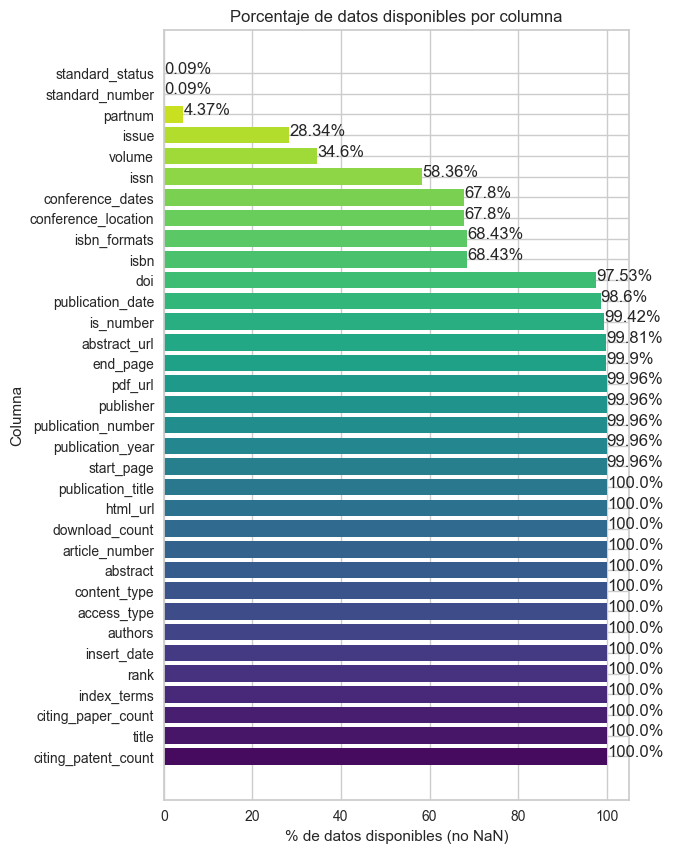

In [139]:
AnalisisNan(data)

In [140]:
fechas = ['publication_date', 'publication_year', 'insert_date']
data[fechas].isna().sum()

publication_date    94
publication_year     3
insert_date          0
dtype: int64

(6708, 7)


title                  object
abstract               object
authors                object
citing_paper_count      int64
citing_patent_count     int64
index_terms            object
insert_date             int64
dtype: object

title                  0
abstract               0
authors                0
citing_paper_count     0
citing_patent_count    0
index_terms            0
insert_date            0
dtype: int64

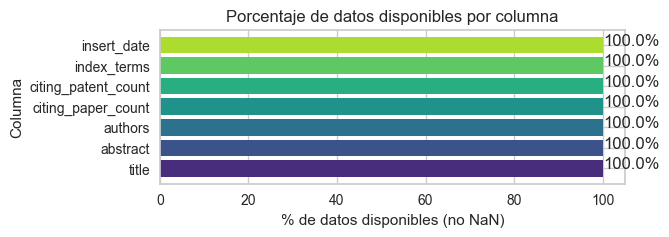

In [141]:
# Atributos importantes
cols2keep = \
['title',
 'abstract',
 'authors',
 'citing_paper_count',
 'citing_patent_count',
 'index_terms',
 'insert_date']

data = data[cols2keep]
print(data.shape)
display(data.dtypes)
display(data.isna().sum().sort_values())

AnalisisNan(data)

In [142]:
# Pasar a minusculas y dejar solo letras
for col in ['title', 'abstract']:
    if data[col].dtype == object:
        data[col] = data[col].str.lower()
        data[col] = data[col].str.replace(r'[^a-z\s]', ' ', regex=True)

In [143]:
data.head()

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date
0,beta ga o in power electronics converters ...,in this work the possibility of using differe...,{'authors': [{'affiliation': 'Electrical Energ...,7,0,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410
1,n selective harmonic elimination pwm for ...,the performance of modular multilevel converte...,{'authors': [{'affiliation': 'Department of El...,75,0,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209
2,mw full bridge mmc for high current low volt...,a full bridge modular multilevel converter mm...,"{'authors': [{'full_name': 'Roland Unruh', 'au...",0,0,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826
3,kv input mhz gan modular multilevel llc co...,a modular multilevel llc converter suitable fo...,{'authors': [{'affiliation': 'Aero-Power Sci-T...,2,0,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527
4,kv kw high voltage ratio bidirectio...,modular multilevel gan based isolated dc dc co...,{'authors': [{'affiliation': 'Center for High ...,0,0,{'ieee_terms': {'terms': ['Multilevel converte...,20250210


In [144]:
a = data.duplicated(subset=['title'] , keep='first').sum()
b = data['title'].unique().shape[0]
a, b, a+b

(99, 6609, 6708)

In [145]:
a = data.duplicated(subset=['abstract'] , keep='first').sum()
b = data['abstract'].unique().shape[0]
a, b, a+b

(23, 6685, 6708)

In [146]:
a = data.duplicated(keep='first').sum()
b = data['abstract'].unique().shape[0]
a, b, a+b

(0, 6685, 6685)

In [147]:
# Eliminar abstracts repetidos
# Si hay Abstract repetido, ordenar por:
# Titulo mas largo
# Publication Year mayor
data_unique = data.copy()
data_unique['Title Length'] = data_unique['title'].str.len()
data_unique = data_unique.sort_values(by=['abstract', 'Title Length', 'insert_date'], ascending=[True, False, False])
data_unique = data_unique.drop_duplicates(subset='abstract', keep='first')
# Ordenar segun indice original
data_unique.sort_index(inplace=True)
# Reset index
data_unique.reset_index(drop=True, inplace=True)
# Eliminar columna extra
data_unique.drop(columns=['Title Length'])
# data filtrado
data = data_unique.copy()
display(data.shape)
display(data.head())

(6685, 8)

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date,Title Length
0,beta ga o in power electronics converters ...,in this work the possibility of using differe...,{'authors': [{'affiliation': 'Electrical Energ...,7,0,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410,73
1,n selective harmonic elimination pwm for ...,the performance of modular multilevel converte...,{'authors': [{'affiliation': 'Department of El...,75,0,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209,143
2,mw full bridge mmc for high current low volt...,a full bridge modular multilevel converter mm...,"{'authors': [{'full_name': 'Roland Unruh', 'au...",0,0,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826,77
3,kv input mhz gan modular multilevel llc co...,a modular multilevel llc converter suitable fo...,{'authors': [{'affiliation': 'Aero-Power Sci-T...,2,0,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527,54
4,kv kw high voltage ratio bidirectio...,modular multilevel gan based isolated dc dc co...,{'authors': [{'affiliation': 'Center for High ...,0,0,{'ieee_terms': {'terms': ['Multilevel converte...,20250210,101


In [148]:
a = data.duplicated(subset=['title'] , keep='first').sum()
b = data['title'].unique().shape[0]
a, b, a+b

(83, 6602, 6685)

In [149]:
idx = data['title'].duplicated(keep='first')
data_rep = data[idx].copy()
data_rep.shape

(83, 8)

In [150]:
sorted(data_rep['title'].value_counts().sort_values().index.tolist(), key=len)

['table of contents',
 'modular multilevel converters',
 'harmonics analysis and simulation of nlm in mmc',
 'the delta configured modular multilevel converter',
 'capacitor selection for modular multilevel converter',
 'a multilevel modular capacitor clamped dc dc converter',
 'a novel reduced switch count multilevel ac ac converter',
 'high power modular multilevel converters with sic jfets',
 'mmc capacitor voltage decoupling and balancing controls',
 'sliding mode control of the modular multilevel converter',
 'control of parallel connected modular multilevel converters',
 'evolution of very high power      mw  medium voltage drives',
 'detailed and averaged models for a     level mmc hvdc system',
 'enhanced equivalent model of the modular multilevel converter',
 'extended controllability of hvdc converters in the vector space',
 'a hybrid modular multilevel converter for solar power integration',
 'accelerated model of modular multilevel converters in pscad emtdc',
 'a bypass lcc

In [151]:
data_rep.loc[data_rep['title'] == 'table of contents', 'abstract'].values

array(['the following topics are dealt with  mppt  solar pv systems  power converters  photovoltaic applications  microgrid control  widebandgap devices  grid converters  telecom power supplies  modulation  electric drives  induction machines  flux switching machines  renewable energy  utility scale battery systems  modular multilevel converters  three phase converter control  ac ac converters  single phase pfc converters  inductive power transfer  electric motors  smart grids  transportation  nonisolated dc dc converters  multiphase converters  dc ac converters  wind energy  grid stability  resonant control  switched capacitor converters  voltage control  synchronous machines  wide band gap power switch modules  dfig based wind systems  wave generation systems  grid connected power converters  off grid power converters  pm machines  energy storage systems  alternative energy systems  single phase ac dc converters  fault diagnostics  machine diagnostics  active power filters  power qua

In [152]:
data = data[data['title'] != 'table of contents'].copy()
data.reset_index(drop=True)
display(data.shape)
data.head()

(6682, 8)

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date,Title Length
0,beta ga o in power electronics converters ...,in this work the possibility of using differe...,{'authors': [{'affiliation': 'Electrical Energ...,7,0,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410,73
1,n selective harmonic elimination pwm for ...,the performance of modular multilevel converte...,{'authors': [{'affiliation': 'Department of El...,75,0,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209,143
2,mw full bridge mmc for high current low volt...,a full bridge modular multilevel converter mm...,"{'authors': [{'full_name': 'Roland Unruh', 'au...",0,0,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826,77
3,kv input mhz gan modular multilevel llc co...,a modular multilevel llc converter suitable fo...,{'authors': [{'affiliation': 'Aero-Power Sci-T...,2,0,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527,54
4,kv kw high voltage ratio bidirectio...,modular multilevel gan based isolated dc dc co...,{'authors': [{'affiliation': 'Center for High ...,0,0,{'ieee_terms': {'terms': ['Multilevel converte...,20250210,101


#### Palabras clave Abstract

In [153]:
# M2C
mask1 = data['abstract'].str.contains('modular')
mask2 = data['abstract'].str.contains('multilevel')
mask3 = data['abstract'].str.contains('converter')
mask4 = mask1 & mask2 & mask3

mask5 = data['abstract'].str.contains('mmc')
mask6 = data['abstract'].str.contains('m2c')

mask7 = mask4 | mask5 | mask6

# M3C
mask8 = data['abstract'].str.contains('modular')
mask9 = data['abstract'].str.contains('multilevel')
mask10 = data['abstract'].str.contains('matrix')
mask11 = data['abstract'].str.contains('converter')
mask12 = mask8 & mask9 & mask10 & mask11

mask13 = data['abstract'].str.contains('mmmc')
mask14 = data['abstract'].str.contains('m3c')

mask15 = mask12 | mask13 | mask14

# Ambos
# mask7 = data['abstract'].str.contains('modular multilevel converter')
# mask15 = data['abstract'].str.contains('modular multilevel matrix converter')

mask = mask7 | mask15
lista_abstract = data.loc[mask, 'abstract'].unique().tolist()
lista_abstract = sorted(lista_abstract, key=len)
len(lista_abstract)

6682

In [154]:
data = data[data['abstract'].isin(lista_abstract)]
data.reset_index(drop=True, inplace=True)
data.shape

(6682, 8)

## Analisis exploratorio

In [155]:
print(data.shape)
display(data.dtypes)
display(data.isna().sum().sort_values())

(6682, 8)


title                  object
abstract               object
authors                object
citing_paper_count      int64
citing_patent_count     int64
index_terms            object
insert_date             int64
Title Length            int64
dtype: object

title                  0
abstract               0
authors                0
citing_paper_count     0
citing_patent_count    0
index_terms            0
insert_date            0
Title Length           0
dtype: int64

Artículo con mayor cantidad de citas

In [156]:
max_citas = data['citing_paper_count'].dropna().max()
max_citas = data[data['citing_paper_count'] == max_citas]
display(max_citas['title'].values)
max_citas

array(['operation  control  and applications of the modular multilevel converter  a review'],
      dtype=object)

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date,Title Length
5150,operation control and applications of the mo...,the modular multilevel converter mmc has bee...,{'authors': [{'affiliation': 'School of Electr...,1879,0,"{'ieee_terms': {'terms': ['Voltage control', '...",20140305,82


Mayor cantidad de citas en patentes

In [157]:
max_citas = data['citing_patent_count'].dropna().max()
max_citas = data[data['citing_patent_count'] == max_citas]
display(max_citas['title'].values)
max_citas

array(['prototype of multiphase modular multilevel converter with   mw power rating and    level output voltage'],
      dtype=object)

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date,Title Length
5533,prototype of multiphase modular multilevel con...,a versatile prototype converter system of the ...,{'authors': [{'affiliation': 'Institute of Pow...,170,31,"{'ieee_terms': {'terms': ['Prototypes', 'Volta...",20050425,103


Mas antiguo

In [158]:
data.sort_values(by='insert_date').head()

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date,Title Length
4880,multilevel voltage source converters for mediu...,in this paper a brief review of multilevel con...,{'authors': [{'affiliation': 'Ansaldo Ricerche...,10,1,"{'ieee_terms': {'terms': ['Medium voltage', 'V...",20020806,79
3853,hybrid multilevel power conversion system a c...,use of multilevel inverters is becoming popula...,{'authors': [{'affiliation': 'Department of El...,30,1,"{'ieee_terms': {'terms': ['Power conversion', ...",20020806,93
3854,hybrid multilevel power conversion system a c...,trends in power semiconductor technology indic...,{'authors': [{'affiliation': 'Department of El...,568,5,"{'ieee_terms': {'terms': ['Power conversion', ...",20020806,93
954,a high frequency mva h bridge building blo...,this paper proposes a mva h bridge buildin...,{'authors': [{'affiliation': 'Center for Power...,19,4,"{'ieee_terms': {'terms': ['Snubbers', 'Inducto...",20020807,116
2977,digitally implemented naturally sampled pwm su...,for dynamic closed loop control of a multileve...,{'authors': [{'affiliation': 'School of Inform...,76,0,{'ieee_terms': {'terms': ['Pulse width modulat...,20031110,85


Publicaciones por año

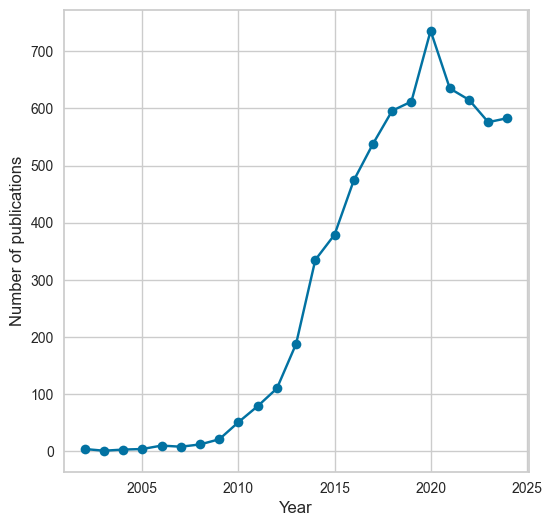

In [159]:
years = data['insert_date'].copy().astype(str).str.extract(r'^(\d{4})').astype(int)

publications_per_year = years[years.values < 2025].value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.plot(publications_per_year.index.get_level_values(0), publications_per_year.values, marker='o', linestyle='-', color='b')

# plt.title('Number of publications per year', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of publications', fontsize=12)

plt.grid(True)

plt.savefig('Data/Figuras/publications_per_year.pdf')

plt.show()

# Preprocesamiento de texto

## Seleccion de atributos

In [ ]:
cols2keep = ['title', 'abstract']
data = data[cols2keep]
data.shape
data.drop_duplicates(subset=cols2keep, inplace=True)
data.shape

(6682, 2)

In [161]:
df = data.copy()

In [162]:
# Todo el preprocesamiento (stopwords, puntuacion, minusculas, lematizacion, etc)
remove_words = ["use", "base", "propose", "present", "method", "system", "paper", "is", "in", "as", "by", "for", "at", "the", "they", "are", "to", "can"]
remove_words = []
for column in data.columns:
    df[column] = df[column].apply(preprocess_text)

## Vectorizacion

In [ ]:
df_vectorized = pd.DataFrame(df['abstract'], columns=['abstract'])

# Vocabulario
vocabulary = ' '.join(df_vectorized['abstract']).split(' ')

# Vectorizacion TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1, 1))
X_vectorized = vectorizer.fit_transform(df['abstract'])
words = vectorizer.get_feature_names_out()
df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

MemoryError: Unable to allocate 11.4 GiB for an array with shape (6682, 228654) and data type float64

In [166]:
df_vectorized.columns

Index(['aa', 'aa mmc', 'aa state', 'aa time', 'aaac', 'aaac topology', 'aac',
       'aac also', 'aac always', 'aac arm',
       ...
       'zvs turn', 'zvs utilizing', 'zvs wide', 'zvs zero', 'zynq',
       'zynq fpga', 'zynq multiprocessing', 'zynq soc', 'zynq system',
       'zynq ultrascale'],
      dtype='object', length=239228)

In [167]:
len(words), len(vocabulary)

(239228, 671780)

In [168]:
len(set(words)), len(set(vocabulary))

(239228, 10597)

In [169]:
len(set(words) - set(vocabulary))

228654

In [170]:
len(set(vocabulary) - set(words))

23

In [171]:
len(data) # Cantidad de papers

6682

In [172]:
# Palabras ordenadas segun puntaje Tfidf, descendente
(df_vectorized == 0).sum().sort_values()

modular                     0
multilevel                  0
converter                   2
modular multilevel        335
multilevel converter      789
                         ... 
generation five          6681
generation flexible      6681
generation formulated    6681
generation evaluation    6681
zynq ultrascale          6681
Length: 239228, dtype: int64

# KNN search

In [173]:
X_vectorized.shape, data.shape

((6682, 239228), (6682, 2))

In [174]:
n_neighbors = 100
knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine').fit(X_vectorized)

# # Topico "crudo"
# topico = ["the study of artificial intelligence and its impact on society"]
# topico = ["reinforcement learning control modular multilevel matrix converter"]
# topico = ["reinforcement learning control modular power converter"]
# topico = ["physics informed reinforcement learning"]
# topico = ["reinforcement learning"]
# topico = ["control power converter balance capacitor"]
# topico = ["artificial intelligence reinforcement learning control power converter balance capacitor"]
topico = ["the artificial intelligence, deep learning, reinforcement learning and neural networks in power converters"]
print(topico)

# Preprocesar
topico = [preprocess_text(topico[0])]
print(topico)

# Vectorizar
topico_vec = vectorizer.transform(topico)
print(topico_vec)

distances_knn, indices_knn = knn.kneighbors(topico_vec)

for i, idx in enumerate(indices_knn[0]):
    display(f"Vecino {i+1}:")
    display(f"Título: {data['title'][idx]}")
    display(f"Abstract: {data['abstract'][idx]}")
    print("-"*40)

['the artificial intelligence, deep learning, reinforcement learning and neural networks in power converters']
['artificial intelligence deep learning reinforcement learning neural network power converter']
  (0, 15370)	0.2531467846391475
  (0, 15374)	0.28286493979711025
  (0, 46971)	0.03770279997433209
  (0, 55469)	0.24273437539262366
  (0, 55478)	0.34352709859378483
  (0, 111389)	0.27599296347242885
  (0, 118250)	0.4734779710353441
  (0, 143022)	0.1296909299046013
  (0, 143334)	0.27599296347242885
  (0, 143489)	0.21533080467575427
  (0, 143491)	0.21726412682835367
  (0, 160767)	0.05687769366698521
  (0, 160928)	0.15673445153702936
  (0, 177878)	0.2792725543950009
  (0, 177881)	0.291275559082078


'Vecino 1:'

'Título: application of neural network controller and policy gradient reinforcement learning on modular multilevel converter  mmc    a proof of concept'

'Abstract: nowadays deep reinforcement learning method has been introduced to power electronic converter control  but the current applications are relatively simple since the converter needing to be controlled has only a few variables  applying the deep reinforcement learning method on the complicated converter with more variables has not been seen yet  this paper shows that the reinforcement learning also has potential to control a complicated modular multilevel converter  mmc   in our method  the capacitor voltages of submodules  sms   arm currents and output currents are directly sent to a neural network controller  and the outputs of the controller are used as the gating signals of the sms directly  the policy gradient  pg  based reinforcement learning algorithm is used without knowing any model information of the mmc  after learning  all the variables in the mmc can be well controlled  i e   the output current can track to the reference  the capacitor voltage of sms can be well ba

----------------------------------------


...

----------------------------------------


'Vecino 100:'

'Título: complementing ac and dc terminal stability analyses of mmc with circulating current inner loop impedance model'

'Abstract: learning from two level voltage source converters  the existing impedance based stability analyses of modular multilevel converters  mmcs  focus on system modes with finite closed loop transfer functions  which consider perturbations of the current flowing into the interconnected ac dc terminal as the input  however  this approach is insufficient for mmcs due to the actively controlled circulating current circuits  resulting from the distributed modulation of each arm and the circulating current control  ccc   to address this limitation  two cases that are not covered by the ac dc terminal stability analysis are initially presented to support the conjecture  subsequently  an inner loop impedance involving the circulating circuit is established  which considers the dynamics of interconnected terminals and divides the injected voltage perturbation by the corresponding current perturbation  to avoid the right half plane pole check of the nyquist criterion and improve the accura

----------------------------------------


# Reduccion de dimensionalidad

### PCA

In [175]:
# PCA 2D
X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
df['pca2d_1'] = X_pca_2d[:, 0]
df['pca2d_2'] = X_pca_2d[:, 1]

# PCA 3D
X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
df['pca3d_1'] = X_pca_3d[:, 0]
df['pca3d_2'] = X_pca_3d[:, 1]
df['pca3d_3'] = X_pca_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[indices_knn[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'pca2d_1'], 
               y=df.loc[indices_knn[0], 'pca2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[indices_knn[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'pca3d_1'], 
                 y=df.loc[indices_knn[0], 'pca3d_2'], 
                 z=df.loc[indices_knn[0], 'pca3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[indices_knn[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
fig.show()

### UMAP

In [176]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0)
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0)
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[indices_knn[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'umap2d_1'], 
               y=df.loc[indices_knn[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[indices_knn[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'umap3d_1'], 
                 y=df.loc[indices_knn[0], 'umap3d_2'], 
                 z=df.loc[indices_knn[0], 'umap3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[indices_knn[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



MemoryError: Unable to allocate 5.95 GiB for an array with shape (6682, 239228) and data type float32

# Clustering

Elegir cantidad de tópicos

In [494]:
k = 15
clusters = list(range(k))
clusters

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

In [478]:
# Asignar esto despues en el clustering o el metodo que sea para identificar el topico consultado
# df.loc[indices_knn[0], "cluster_xx"] = k+2

* DBScan no sirve por que los textos son muy similares
* El método del codo puede ser reemplazado por inspección visual


## Clustering jerárquico

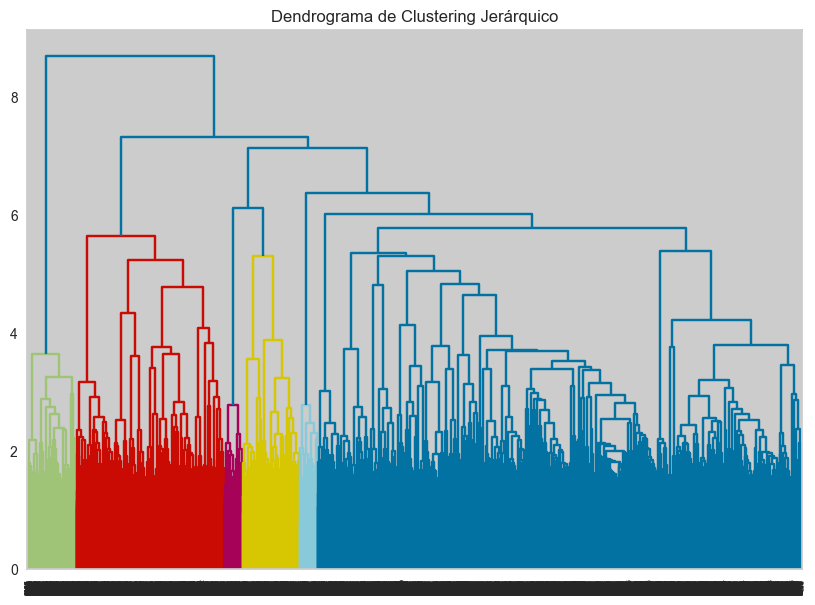

In [479]:
Z = linkage(df_vectorized, method='ward') # Crear cluster jerarquico con distancia del coseno
joblib.dump(Z, 'Data/API/hierarchical_cluster_Z.joblib') # Guardar cluster
Z = joblib.load('Data/API/hierarchical_cluster_Z.joblib') # Cargar de cluster hecho de antes
plt.figure(figsize=(10, 7))
plt.title("Dendrograma de Clustering Jerárquico")
dendrogram(Z)
plt.show()

In [480]:
# Ajustar automaticamente la distancia umbral para tener k clusters

distancia_umbral = 0
clusters_HC = set(range(k+1))
while len(clusters_HC) > k:
    clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
    distancia_umbral += 1
distancia_umbral -= 2
clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)

while len(clusters_HC) > k:
    clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
    distancia_umbral += 0.1
distancia_umbral -= 0.2
clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)

while len(clusters_HC) > k:
    clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
    distancia_umbral += 0.01
distancia_umbral -= 0.02
clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)

while len(clusters_HC) > k:
    clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
    distancia_umbral += 0.001
# distancia_umbral -= 0.002

display(set(clusters_HC))
display(distancia_umbral)

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14}

4.831999999999996

In [495]:
# Definir la función para ajustar la distancia umbral
def ajustar_distancia_umbral(Z, k):
    min_dist = 0
    max_dist = max(Z[:, 2])
    
    while min_dist < max_dist:
        mid_dist = (min_dist + max_dist) / 2
        clusters_HC = fcluster(Z, mid_dist, criterion='distance') - 1
        num_clusters = len(set(clusters_HC))
        
        if num_clusters > k:
            min_dist = mid_dist + 1e-5  # Ajustar el límite inferior
        elif num_clusters < k:
            max_dist = mid_dist - 1e-5  # Ajustar el límite superior
        else:
            return clusters_HC, mid_dist
    
    return clusters_HC, mid_dist

# Rango de clusters deseado
cluster_range = range(3, 21)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
distancias_umbral = {}

# Obtener distancias umbrales para cada número de clusters en el rango
for k_value in cluster_range:
    clusters_HC, distancia_umbral = ajustar_distancia_umbral(Z, k_value)
    distancias_umbral[k_value] = distancia_umbral
    print(f'Número de clusters: {k_value}, Distancia umbral: {distancia_umbral}')

# Mostrar las distancias umbrales para cada número de clusters
print(distancias_umbral)

Número de clusters: 3, Distancia umbral: 7.206888206036425
Número de clusters: 4, Distancia umbral: 6.526992148863178
Número de clusters: 5, Distancia umbral: 6.255033725993878
Número de clusters: 6, Distancia umbral: 6.119054514559229
Número de clusters: 7, Distancia umbral: 5.983075303124579
Número de clusters: 8, Distancia umbral: 5.711116880255281
Número de clusters: 9, Distancia umbral: 5.4391584573859815
Número de clusters: 10, Distancia umbral: 5.371168851668656
Número de clusters: 11, Distancia umbral: 5.337174048809994
Número de clusters: 12, Distancia umbral: 5.309154894891332
Número de clusters: 13, Distancia umbral: 5.303179245951332
Número de clusters: 14, Distancia umbral: 5.167200034516682
Número de clusters: 15, Distancia umbral: 4.895241611647384
Número de clusters: 16, Distancia umbral: 4.827252005930059
Número de clusters: 17, Distancia umbral: 4.793257203071397
Número de clusters: 18, Distancia umbral: 4.759262400212734
Número de clusters: 19, Distancia umbral: 4.35

In [496]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, distancias_umbral[k], criterion='distance') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


cluster_HC
12    2011
14    1155
3      678
0      427
1      326
6      320
2      272
9      258
11     235
10     231
8      193
5      172
4      158
7      155
13      95
Name: count, dtype: int64

## Kmeans

### Metodo del codo

Comenzando KMeans para k=10
Completado en 26.96 segundos

Comenzando KMeans para k=11
Completado en 26.25 segundos

Comenzando KMeans para k=12
Completado en 27.69 segundos

Comenzando KMeans para k=13
Completado en 29.56 segundos

Comenzando KMeans para k=14
Completado en 32.64 segundos

Comenzando KMeans para k=15
Completado en 34.41 segundos

Comenzando KMeans para k=16
Completado en 35.44 segundos

Comenzando KMeans para k=17
Completado en 36.96 segundos

Comenzando KMeans para k=18
Completado en 40.33 segundos

Comenzando KMeans para k=19
Completado en 43.52 segundos

Comenzando KMeans para k=20
Completado en 46.83 segundos



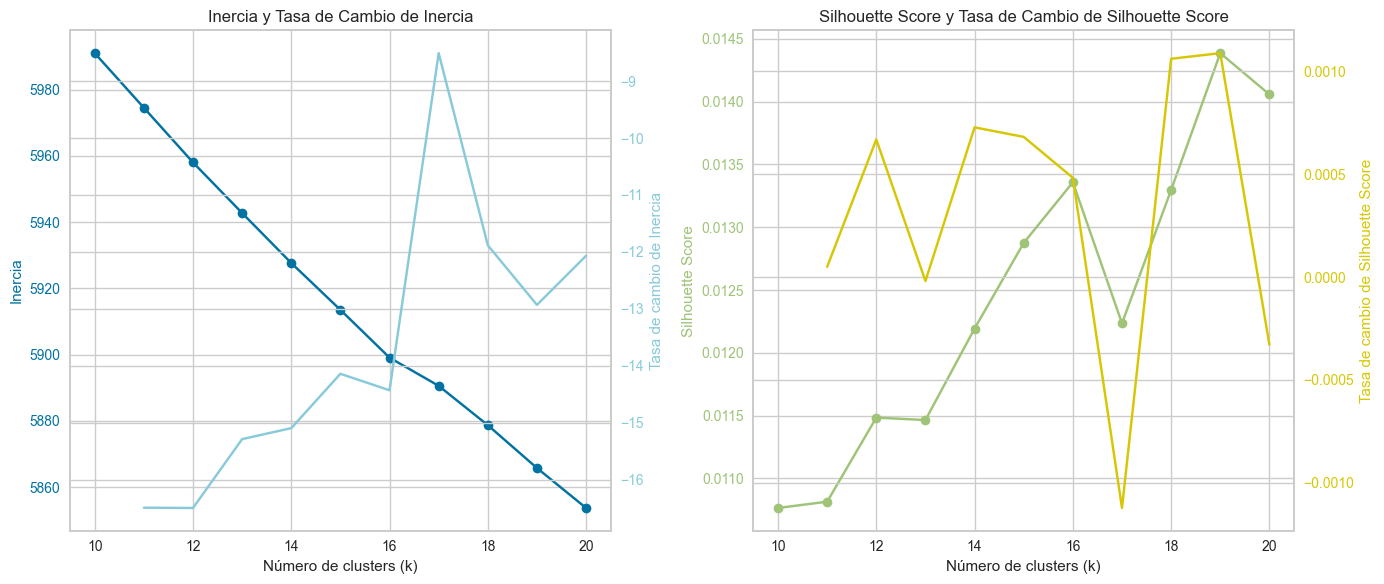

In [ ]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 21)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X_vectorized)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X_vectorized, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('Data/API/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

k_range = range(10, 21)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# Cargar
with open('Data/API/kmeans_metrics.pkl', 'rb') as f:
    metrics = pickle.load(f)
inertia = metrics['inertia']
silhouette_scores = metrics['silhouette_scores']

# Calcular la tasa de cambio para la inercia y el Silhouette Score
delta_inertia = np.diff(inertia)
delta_silhouette = np.diff(silhouette_scores)

# Crear una figura con dos subgráficos (lado a lado)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Graficar la inercia en el primer subgráfico (izquierda)
ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Inercia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# Graficar la tasa de cambio de la inercia en el eje y derecho
ax1_twin = ax1.twinx()
ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
ax1_twin.tick_params(axis='y', labelcolor='c')

# Título y leyenda para el primer gráfico
ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# ax1.legend(loc='best')

# Graficar el Silhouette Score en el segundo subgráfico (derecha)
ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
ax2.set_xlabel('Número de clusters (k)')
ax2.set_ylabel('Silhouette Score', color='g')
ax2.tick_params(axis='y', labelcolor='g')

# Graficar la tasa de cambio del Silhouette Score en el eje y derecho
ax2_twin = ax2.twinx()
ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
ax2_twin.tick_params(axis='y', labelcolor='y')

# Título y leyenda para el segundo gráfico
ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# ax2.legend(loc='best')

# Mostrar el gráfico
plt.tight_layout()  # Ajusta el espacio entre los subgráficos
plt.show()

### Clustering final

In [497]:
kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X_vectorized)
df["cluster_KM"] = kmeans.predict(X_vectorized)

print(sorted(df['cluster_KM'].unique()))
df["cluster_KM"].value_counts()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


cluster_KM
10    1248
13     998
5      684
3      633
0      429
6      414
12     409
9      377
14     361
2      245
8      224
1      220
11     172
4      169
7      103
Name: count, dtype: int64

Clasificación de un texto

In [499]:
predicted_cluster = kmeans.predict(topico_vec)
print(predicted_cluster)

[10]


### DBScan

In [486]:
# # Graficar distancias a los vecinos mas cercanos para elegir el radio de dbscan
# proj = X_vectorized

# # Inicializar el modelo de vecinos más cercanos con distancia coseno
# nbrs = NearestNeighbors(n_neighbors=100, metric='cosine').fit(proj)

# # Obtener las distancias a los vecinos más cercanos
# distances, _ = nbrs.kneighbors(proj)

# # Extraer la distancia al 5to vecino más cercano
# fifth_neighbor_distance = distances[:, -1]
# # fifth_neighbor_distance = distances[:, 1:].mean(axis=1)

# # Graficar la distribución de distancias
# plt.figure(figsize=(8, 5))
# plt.hist(fifth_neighbor_distance, bins=100, edgecolor='black', alpha=0.7)
# plt.xlabel("Distancia al 5to vecino más cercano")
# plt.ylabel("Frecuencia")
# plt.title("Distribución de distancias al 5to vecino más cercano")
# plt.grid(axis='y', linestyle='--', alpha=0.6)
# plt.show()

In [487]:
# from sklearn.cluster import DBSCAN
# from pyDOE import lhs
# from sklearn.metrics import silhouette_score
# from tqdm import tqdm  # Barra de progreso
# from collections import Counter  # Para contar elementos por cluster

# # Definir el número de muestras en el hipercubo latino
# n_samples = 100  

# # Generar el diseño de hipercubo latino con dos dimensiones (eps y min_samples)
# lhs_samples = lhs(2, samples=n_samples)

# # Escalar las muestras a los rangos deseados
# eps_values = 0.001 + lhs_samples[:, 0] * (1 - 0.001)  # eps entre 0.2 y 0.9
# min_samples_values = 2 + (lhs_samples[:, 1] * (100 - 2)).astype(int)  # min_samples entre 2 y 100

# # Crear un DataFrame para almacenar los resultados
# results = []

# # Barra de progreso con tqdm
# for i, (eps, min_samples) in tqdm(enumerate(zip(eps_values, min_samples_values)), total=n_samples, desc="Evaluando combinaciones"):
#     # Aplicar DBSCAN
#     dbscan = DBSCAN(eps=eps, min_samples=min_samples, metric='cosine')
#     labels = dbscan.fit_predict(df[['umap3d_1', 'umap3d_2', 'umap3d_3']].values)

#     # Contar clusters encontrados (excluyendo el ruido, cluster -1)
#     n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    
#     # Calcular silhouette score solo si hay al menos 2 clusters
#     if n_clusters > 1:
#         score = silhouette_score(df[['umap3d_1', 'umap3d_2', 'umap3d_3']].values, labels, metric='cosine')
#     else:
#         score = np.nan  # No se puede calcular si solo hay 1 cluster
    
#     # Contar la cantidad de elementos por cluster (incluye el ruido -1 si está presente)
#     cluster_counts = dict(Counter(labels))

#     # Guardar los resultados
#     results.append([eps, min_samples, n_clusters, score, cluster_counts])

# # Convertir resultados a DataFrame
# df_results = pd.DataFrame(results, columns=["eps", "min_samples", "n_clusters", "silhouette_score", "cluster_counts"])

# # Mostrar las 10 mejores combinaciones de eps y min_samples según silhouette score
# print(df_results.sort_values(by="silhouette_score", ascending=False).head(10))


In [488]:
# mask1 = df_results['cluster_counts'].apply(lambda x: len(x)).sort_values() < 30
# mask2 = df_results['cluster_counts'].apply(lambda x: len(x)).sort_values() > 3
# df_results['cluster_counts'].apply(lambda x: np.std(list(x.values()))).sort_values()

In [489]:
# from sklearn.cluster import DBSCAN

# # Definir el modelo DBSCAN (ajusta eps y min_samples según tu dataset)
# dbscan = DBSCAN(eps=0.00001, min_samples=100, metric='cosine') 

# # Ajustar el modelo a los datos
# df["cluster_DB"] = dbscan.fit_predict(X_vectorized)

# # Mostrar los clusters encontrados
# print(sorted(df['cluster_DB'].unique()))  # Clusters encontrados
# print(df["cluster_DB"].value_counts())    # Cantidad de puntos por cluster

## Resultados

In [500]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
df.loc[indices_knn[0], "cluster_KM"] = -1
# df.loc[indices_knn[0], "cluster_DBScan"] = -1

Elegir tipo de clustering realizado:
* cluster_HC
* cluster_KM

In [501]:
clustering_method = "cluster_KM"

In [502]:
# PCA

# Calcular los centroides de cada cluster
centroides_2d = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean()
centroides_3d = df.groupby(clustering_method)[['pca3d_1', 'pca3d_2', 'pca3d_3']].mean()

fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales en 2D
fig.add_trace(
    go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
               marker=dict(color=df[clustering_method], colorscale='Viridis', size=3),
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados en 2D
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'pca2d_1'], 
               y=df.loc[indices_knn[0], 'pca2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Centroides en 2D
fig.add_trace(
    go.Scatter(x=centroides_2d['pca2d_1'], 
               y=centroides_2d['pca2d_2'], 
               mode='markers',
               marker=dict(symbol='x', color=centroides_2d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
               text=["Centroide: " + str(c) for c in centroides_2d.index],
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D
fig.add_trace(
    go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
                 marker=dict(color=df[clustering_method], colorscale='Viridis', size=3, opacity=1),
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'pca3d_1'], 
                 y=df.loc[indices_knn[0], 'pca3d_2'], 
                 z=df.loc[indices_knn[0], 'pca3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Centroides en 3D
fig.add_trace(
    go.Scatter3d(x=centroides_3d['pca3d_1'], 
                 y=centroides_3d['pca3d_2'], 
                 z=centroides_3d['pca3d_3'], 
                 mode='markers',
                 marker=dict(symbol='x', color=centroides_3d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
                 text=["Centroide: " + str(c) for c in centroides_3d.index],
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
fig.show()

In [503]:
# UMAP

# Calcular los centroides de cada cluster
centroides_2d = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean()
centroides_3d = df.groupby(clustering_method)[['umap3d_1', 'umap3d_2', 'umap3d_3']].mean()

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales en 2D
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=df[clustering_method], colorscale='Viridis', size=3),
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados en 2D
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'umap2d_1'], 
               y=df.loc[indices_knn[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Centroides en 2D
fig.add_trace(
    go.Scatter(x=centroides_2d['umap2d_1'], 
               y=centroides_2d['umap2d_2'], 
               mode='markers',
               marker=dict(symbol='x', color=centroides_2d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
               text=["Centroide: " + str(c) for c in centroides_2d.index],
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=df[clustering_method], colorscale='Viridis', size=3, opacity=1),
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'umap3d_1'], 
                 y=df.loc[indices_knn[0], 'umap3d_2'], 
                 z=df.loc[indices_knn[0], 'umap3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Centroides en 3D
fig.add_trace(
    go.Scatter3d(x=centroides_3d['umap3d_1'], 
                 y=centroides_3d['umap3d_2'], 
                 z=centroides_3d['umap3d_3'], 
                 mode='markers',
                 marker=dict(symbol='x', color=centroides_3d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
                 text=["Centroide: " + str(c) for c in centroides_3d.index],
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

# Sumarizacion
Nube de palabras en corpus completo y por clusters

### Corpus


Corpus completo: mmc, voltage, dc, control, converter, power, current, system, fault, proposed


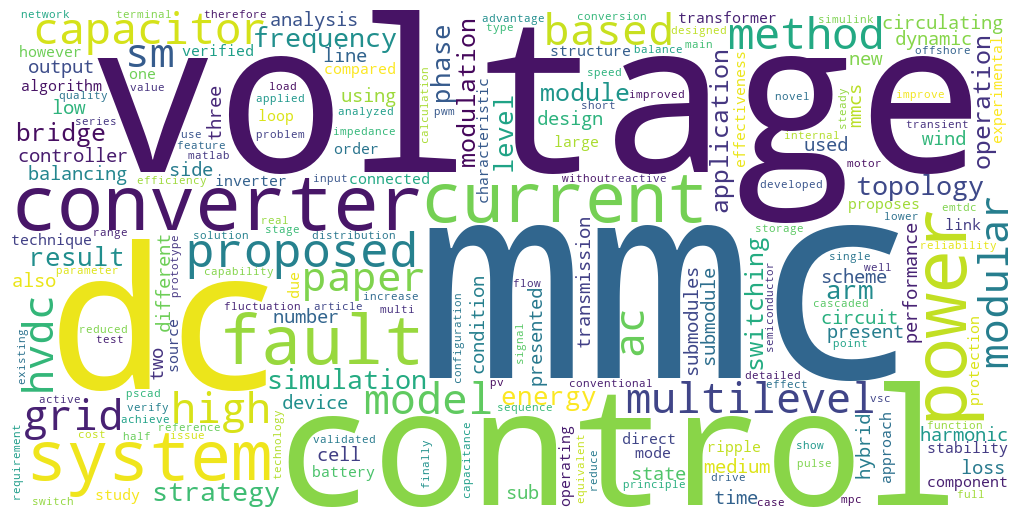

In [110]:
centroide = df_vectorized.mean(axis=0)
print(f'\nCorpus completo: {", ".join([words[ind] for ind in centroide.argsort()[::-1][:10]])}')

NubePalabrasTFIDF(centroide)

### Clusters

In [111]:
for cluster in clusters:
    cluster_data = df_vectorized[(df[clustering_method] == cluster).values]
    centroide = cluster_data.mean(axis=0)
    print(f'\nCluster {cluster}: {", ".join([words[ind] for ind in centroide.argsort()[::-1][:10]])}')
    # NubePalabrasTFIDF(centroide)


Cluster 0: voltage, capacitor, balancing, mmc, control, proposed, module, method, arm, converter

Cluster 1: mpc, control, predictive, model, current, mmc, proposed, method, voltage, circulating

Cluster 2: dc, converter, voltage, ac, power, transformer, topology, high, proposed, control

Cluster 3: drive, motor, speed, voltage, frequency, low, machine, capacitor, control, converter

Cluster 4: battery, storage, energy, system, bess, power, control, converter, cell, soc

Cluster 5: current, circulating, control, mmc, voltage, harmonic, controller, arm, proposed, component

Cluster 6: fault, dc, current, protection, mmc, circuit, hvdc, line, system, proposed

Cluster 7: model, mmc, time, simulation, dynamic, system, transient, accuracy, equivalent, converter

Cluster 8: hvdc, system, control, mmc, power, transmission, grid, dc, voltage, vsc

Cluster 9: pv, power, photovoltaic, system, grid, dc, mppt, maximum, solar, converter

Cluster 10: modulation, pwm, voltage, switching, carrier, l

# Documento representativo
En corpus completo y por clusters

## Centroides

In [ ]:
def encontrar_mas_cercano_al_centroide(df_vectorized, data):
    centroide = df_vectorized.mean(axis=0)
    distancias = euclidean_distances(df_vectorized, [centroide])
    indice_mas_cercano = np.argmin(distancias)
    texto_mas_cercano = data.iloc[indice_mas_cercano]['Abstract']
    titulo = data.iloc[indice_mas_cercano]['title']
    return titulo, texto_mas_cercano

### Corpus

In [113]:
titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
display(f"Texto mas representativo del corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {texto_mas_cercano}")

'Texto mas representativo del corpus:'

'Título: a control method of dc capacitor voltage in mmc for hvdc system using negative sequence current'

'Abstract: the application of modular multilevel converter (mmc) for high voltage direct current (hvdc) system is expected to enhance power transmission capacity and improve power system stability. to control an mmc hvdc system properly, the ac current, circulating current among arms and submodule (sm) capacitor voltages are considered. in the conventional balance control method of the dc capacitor voltage, the reference value of the circulating current control includes ac component as same frequency as ac grid. in this case, it is difficult to follow the reference value perfectly by proportional integral (pi) controller. this article presents a new control method of dc capacitor voltage using negative sequence of ac grid current and circulating current. the validity of the proposed control method is verified by a numerical simulation.'

### Clusters

In [114]:
for cluster in clusters:
    cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
    cluster_data = data[df[clustering_method] == cluster]
    titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
    display(f"Cluster {cluster}: Texto mas cercano al centroide")
    display(f"Título: {titulo}")
    display(f"Abstract: {texto_mas_cercano}")

'Cluster 0: Texto mas cercano al centroide'

'Título: a control method for voltage balancing in modular multilevel converters'

'Abstract: the modular multilevel converter (mmc) is attractive for medium  or high power applications because of the advantages of its high modularity, availability, and high power quality. the voltage balancing of the floating capacitors in the cascaded submodules of the mmc is a key issue. in this paper, a voltage balancing control method is proposed. this method uses the phase shifted carrier based pulsewidth modulation scheme to control high frequency current components for capacitor voltage balancing in the mmc without measuring the arm currents. simulations and experimental studies of the mmc were conducted, and the results confirm the effectiveness of the proposed capacitor voltage balancing control method.'

'Cluster 1: Texto mas cercano al centroide'

'Título: an improved indirect model predictive control approach for modular multilevel converter'

...

'Título: control and modelling of offshore wind farms using high capacity wind generators and mmc hvdc transmission'

'Abstract: modular multi level converter based high voltage direct current (mmc hvdc) technology and high capacity wind generators have emerged as a leading solution for offshore wind power transmission. this paper proposes a control strategy for 66kv10mw wind turbines and the mmc, and constructs a comprehensive model of the offshore wind power transmission system. the effectiveness of the control scheme is then verified through transient simulation. the proposed control strategy ensures the stability of the wind farm side ac voltage, frequency, and dc voltage while also allowing for flexible adjustments to the amount of reactive power output to the ac power grid.'

'Cluster 14: Texto mas cercano al centroide'

'Título: accurate impedance modeling and control strategy for improving the stability of dc system in multiterminal mmc based dc grid'

'Abstract: this article proposes an accurate dc side impedance modeling method of modular multilevel converter (mmc) and a control strategy for improving the stability of the dc system in mmc based dc grid. first, the impedance modeling method based on harmonic linearization is adopted to establish the dc side small signal impedance model of mmc, which considers the internal multiharmonic coupling characteristics and the complete control system. second, an equivalent model is established to analyze the frequency impedance characteristics of the dc ports in mmc based dc grid, and the stability of dc ports is further analyzed based on the impedance based stability criterion. then, considering both the dynamic characteristics and stability of the dc system, a specific design method of controller parameter optimization and additional virtual damping controller is proposed. based on matlab/simulink, a detailed time domain simulation model of mmc based dc grid is established. the simulation 

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [ ]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
print("Texto más representativo del corpus:")
print(f"Título: {data['title'].iloc[abstract00]}")
print(f"Abstract: {data['Abstract'].iloc[abstract00]}")

Texto más representativo del corpus:
Título: transformation of the energy system in germany   enhancement of system stability by integration of innovative multilevel hvdc in the ac grid
Abstract: globally, deregulation and privatization are posing new challenges on high voltage transmission and on distribution systems as well. an increasingly liberalized market will encourage trading opportunities to be identified and developed. environmental constraints, such as energy saving, and co2 reduction, also play an important role. the loading of existing power systems will further increase, leading to bottlenecks and reliability problems. consequently, we have to deal with an area of conflicts between reliability of supply, environmental sustainability as well as economic efficiency. furthermore, in germany, the transition from well proven energy mix to the new energy transition ("energie wende") with large amounts of volatile regenerative energy sources (res), e.g. over 30 gw solar power on

### Clusters

In [ ]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
display("Texto más representativo del corpus:")
display(f"Título: {data['title'].iloc[abstract00]}")
display(f"Abstract: {data['Abstract'].iloc[abstract00]}")

'Texto más representativo del corpus:'

'Título: transformation of the energy system in germany   enhancement of system stability by integration of innovative multilevel hvdc in the ac grid'

'Abstract: globally, deregulation and privatization are posing new challenges on high voltage transmission and on distribution systems as well. an increasingly liberalized market will encourage trading opportunities to be identified and developed. environmental constraints, such as energy saving, and co2 reduction, also play an important role. the loading of existing power systems will further increase, leading to bottlenecks and reliability problems. consequently, we have to deal with an area of conflicts between reliability of supply, environmental sustainability as well as economic efficiency. furthermore, in germany, the transition from well proven energy mix to the new energy transition ("energie wende") with large amounts of volatile regenerative energy sources (res), e.g. over 30 gw solar power on medium and even low voltage level, in combination with over 30 gw of wind power (at present   mainly onshore) plus high amounts of offshore wind power in the future (30 to 50 gw   long

In [ ]:
for cluster in clusters:
    abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
    display(f"Cluster {cluster}: Texto mas representativo")
    display(f"Título: {data['title'].iloc[abstract00]}")
    display(f"Abstract: {data['Abstract'].iloc[abstract00]}")

'Cluster 0: Texto mas representativo'

'Título: voltage estimation in combination with level adjusted phase shifted carrier modulation (la psc) for sensorless balancing of diode clamped modular multilevel converters (mmcs)'

'Abstract: the modular multilevel converter (mmc) is a popular solution in high voltage applications with significant potential in others. however, its stable operation is at the expense of numerous sensors, high communication burden, and complicated balancing strategies, which reduce its cost effectiveness. hence, the introduction of a sensorless voltage balancing strategy with a simple controller is an attractive objective. the diode clamped mmc offers the simplest and yet a highly effective solution for creating a balancing path between two modules through a diode with a fraction of the rated current. to compensate the lack of bidirectional energy transfer, a modified modulation technique is necessary. level adjusted phase shifted carrier (la psc) modulation introduces a small circulating current that ensures the correct balancing direction. although the open loop operation is possible, monitoring and protection functions may still necessitate the independent tracking of the modules

'Cluster 1: Texto mas representativo'

'Título: interfacing an electric vehicle to the grid with modular conversion unit: a case study of a charging station and its control framework'

...

'Título: real time validation of a dc link tuning method for an ac ac wind converter in fractional frequency transmission system'

'Abstract: wind power converters with modularity and scalability features paly pivotal role in interfacing of wind farms with the medium/high power systems. these offshore or onshore grids are vulnerable to instabilities during certain working conditions that adaptive control solutions could overcome some of those stability issues. additionally, computational burden of existing control strategies, such as model predictive control (mpc) has caused implementation barriers. in this work, the operational performance of the modular multilevel matrix converter (m3c) is assessed to transmit power produced from offshore wind farm to interconnect with onshore ac grid. small signal impedance measurement based stability analysis are not efficient to predict large signal stability characteristics. the two layer control design architecture is proposed to regulate the converter branch voltages and currents. the second layer iterative controller is embedded into an integrated perturbation analysis an

'Cluster 14: Texto mas representativo'

'Título: modeling and harmonic stability of mmc hvdc with passive circulating current filters'

'Abstract: a modular multilevel converter (mmc) is an emerging converter technology widely used in wind power applications using high voltage direct current (hvdc) transmission, and it has been largely investigated in medium voltage solar harvesting as well as electric motor drives. different from studies dealing with active circulating current control loops, this paper focuses on impedance modeling and harmonic stability studies for mmcs with passive circulating current filters (pccfs). a power stage circuit including a pccf is transformed and remodeled to obtain small signal formulations. this transformation leads to additional high order matrix computing complexity due to the added impedance subnetwork matrix from the pccf as well as relevant crossed frequency impacts. to simplify the computational burden, the proposed model aims to solve one arm equation instead of all six mmc arm equations. to achieve this result, additional challenges occur when the mmc is connected to a renewabl

Anti representantes (abstracts con baja participación en el tfid vectorizer)

In [ ]:
# representantes = [df_vectorized.loc[df[df[clustering_method] == idx].index].sum(axis=1).sort_values().index[0] for idx in clusters]
# for rep in representantes:
#   print('\nTítulo:')
#   display(data.iloc[rep]['title'])
#   print('\nAbstract')
#   display(data.iloc[rep]['Abstract'])

## Similaridad del coseno

### Corpus

In [ ]:
abstract00 = RepresentanteCoseno(df_vectorized)
titulo = data["title"].iloc[abstract00]
abstract_mas_representativo = data["Abstract"].iloc[abstract00]

display(f"Texto mas similar a todos los demas en el corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {abstract_mas_representativo}")

'Texto mas similar a todos los demas en el corpus:'

'Título: a control method of dc capacitor voltage in mmc for hvdc system using negative sequence current'

'Abstract: the application of modular multilevel converter (mmc) for high voltage direct current (hvdc) system is expected to enhance power transmission capacity and improve power system stability. to control an mmc hvdc system properly, the ac current, circulating current among arms and submodule (sm) capacitor voltages are considered. in the conventional balance control method of the dc capacitor voltage, the reference value of the circulating current control includes ac component as same frequency as ac grid. in this case, it is difficult to follow the reference value perfectly by proportional integral (pi) controller. this article presents a new control method of dc capacitor voltage using negative sequence of ac grid current and circulating current. the validity of the proposed control method is verified by a numerical simulation.'

### Clusters

In [ ]:
for cluster in clusters:
    abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
    titulo = data["title"].iloc[abstract00]
    abstract_mas_representativo = data["Abstract"].iloc[abstract00]
    display(f"Cluster {cluster}: Texto mas similar a todos en el cluster")
    display(f"Título: {titulo}")
    display(f"Abstract: {abstract_mas_representativo}")

'Cluster 0: Texto mas similar a todos en el cluster'

'Título: semi full bridge submodule for modular multilevel converters'

'Abstract: the energy variations in each arm of the modular multilevel converter comprises two components. the first component relates to the difference between the instantaneous input and output power of each phase leg, and the second component relates to the energy which is moved back and forth between the two arms of the phase leg. the latter component can be reduced or even eliminated if the peak to peak amplitude of the alternating voltage is greater than the pole to pole voltage of the dc link. this will, however, require submodules which can insert negative voltages. therefore, a semi full bridge submodule which uses less semiconductors than the conventional full bridge is proposed. simulation results shows that by using the negative voltage levels the capacitor voltage ripple can be reduced by up to 59%. experimental results also shows that a 7 level voltage waveform can be generated using only one semi full bridge submodule with two capacitors per arm.'

'Cluster 1: Texto mas similar a todos en el cluster'

'Título: modelling, simulation and analysis of a modular multilevel converter for medium voltage applications'

...

"Título: fault detection in multilevel cascaded inverter using park's vector approach with balanced battery power usage"

"Abstract: among the multilevel converter topologies the cascaded h bridge converter (mchbc) differs from other topologies by having series connections of several power cells, producing a better voltage quality and higher voltage output range, and using the same voltage power supply levels. this characteristic adds several benefits as it allows a modular system, the use of low voltage power supplies, and output voltage waveforms with low level of harmonic distortion. having more semiconductors than a conventional 2 level voltage source inverter (vsi) the probability of a fault occurrence is bigger, and therefore the importance of having a system that can pinpoint the malfunctioning device is higher. this paper presents an integrated method to control a 3 phase mchbc capable of distributing the energy uniformly by all batteries and simultaneously diagnose isolated gate bipolar transistors (igbts) open circuit faults in the converter cells, using the phase voltage park's vector component

'Cluster 14: Texto mas similar a todos en el cluster'

'Título: system integration and demonstration of a 4.5 mva statcom based on emitter turn off (eto) thyristor and cascade multilevel converter'

'Abstract: static synchronous compensator (statcom), providing quick and robust voltage support, is an "enabling infrastructure technology" for power engineering today. the emitter turn off (eto) thyristor, as an emerging kilohertz power semiconductor device, provides significant advantages over other competing power switch technologies and will result in a fast response statcom system with reduced overall cost per kva. meanwhile, the cascade multilevel converter (cmc) is the most feasible topology for statcom because of its compact structure, fast response, clean power quality, easy modularity and scalability. combining advanced switch technology, modular converter technology and control technology, a 4.5 mva statcom system is developed. this paper discusses system integration of the statcom with emphasis on power stage design and verification, digital controller design and verification. finally, the grid tie system demonstration of statcom is presented.'

# Grafo de palabras

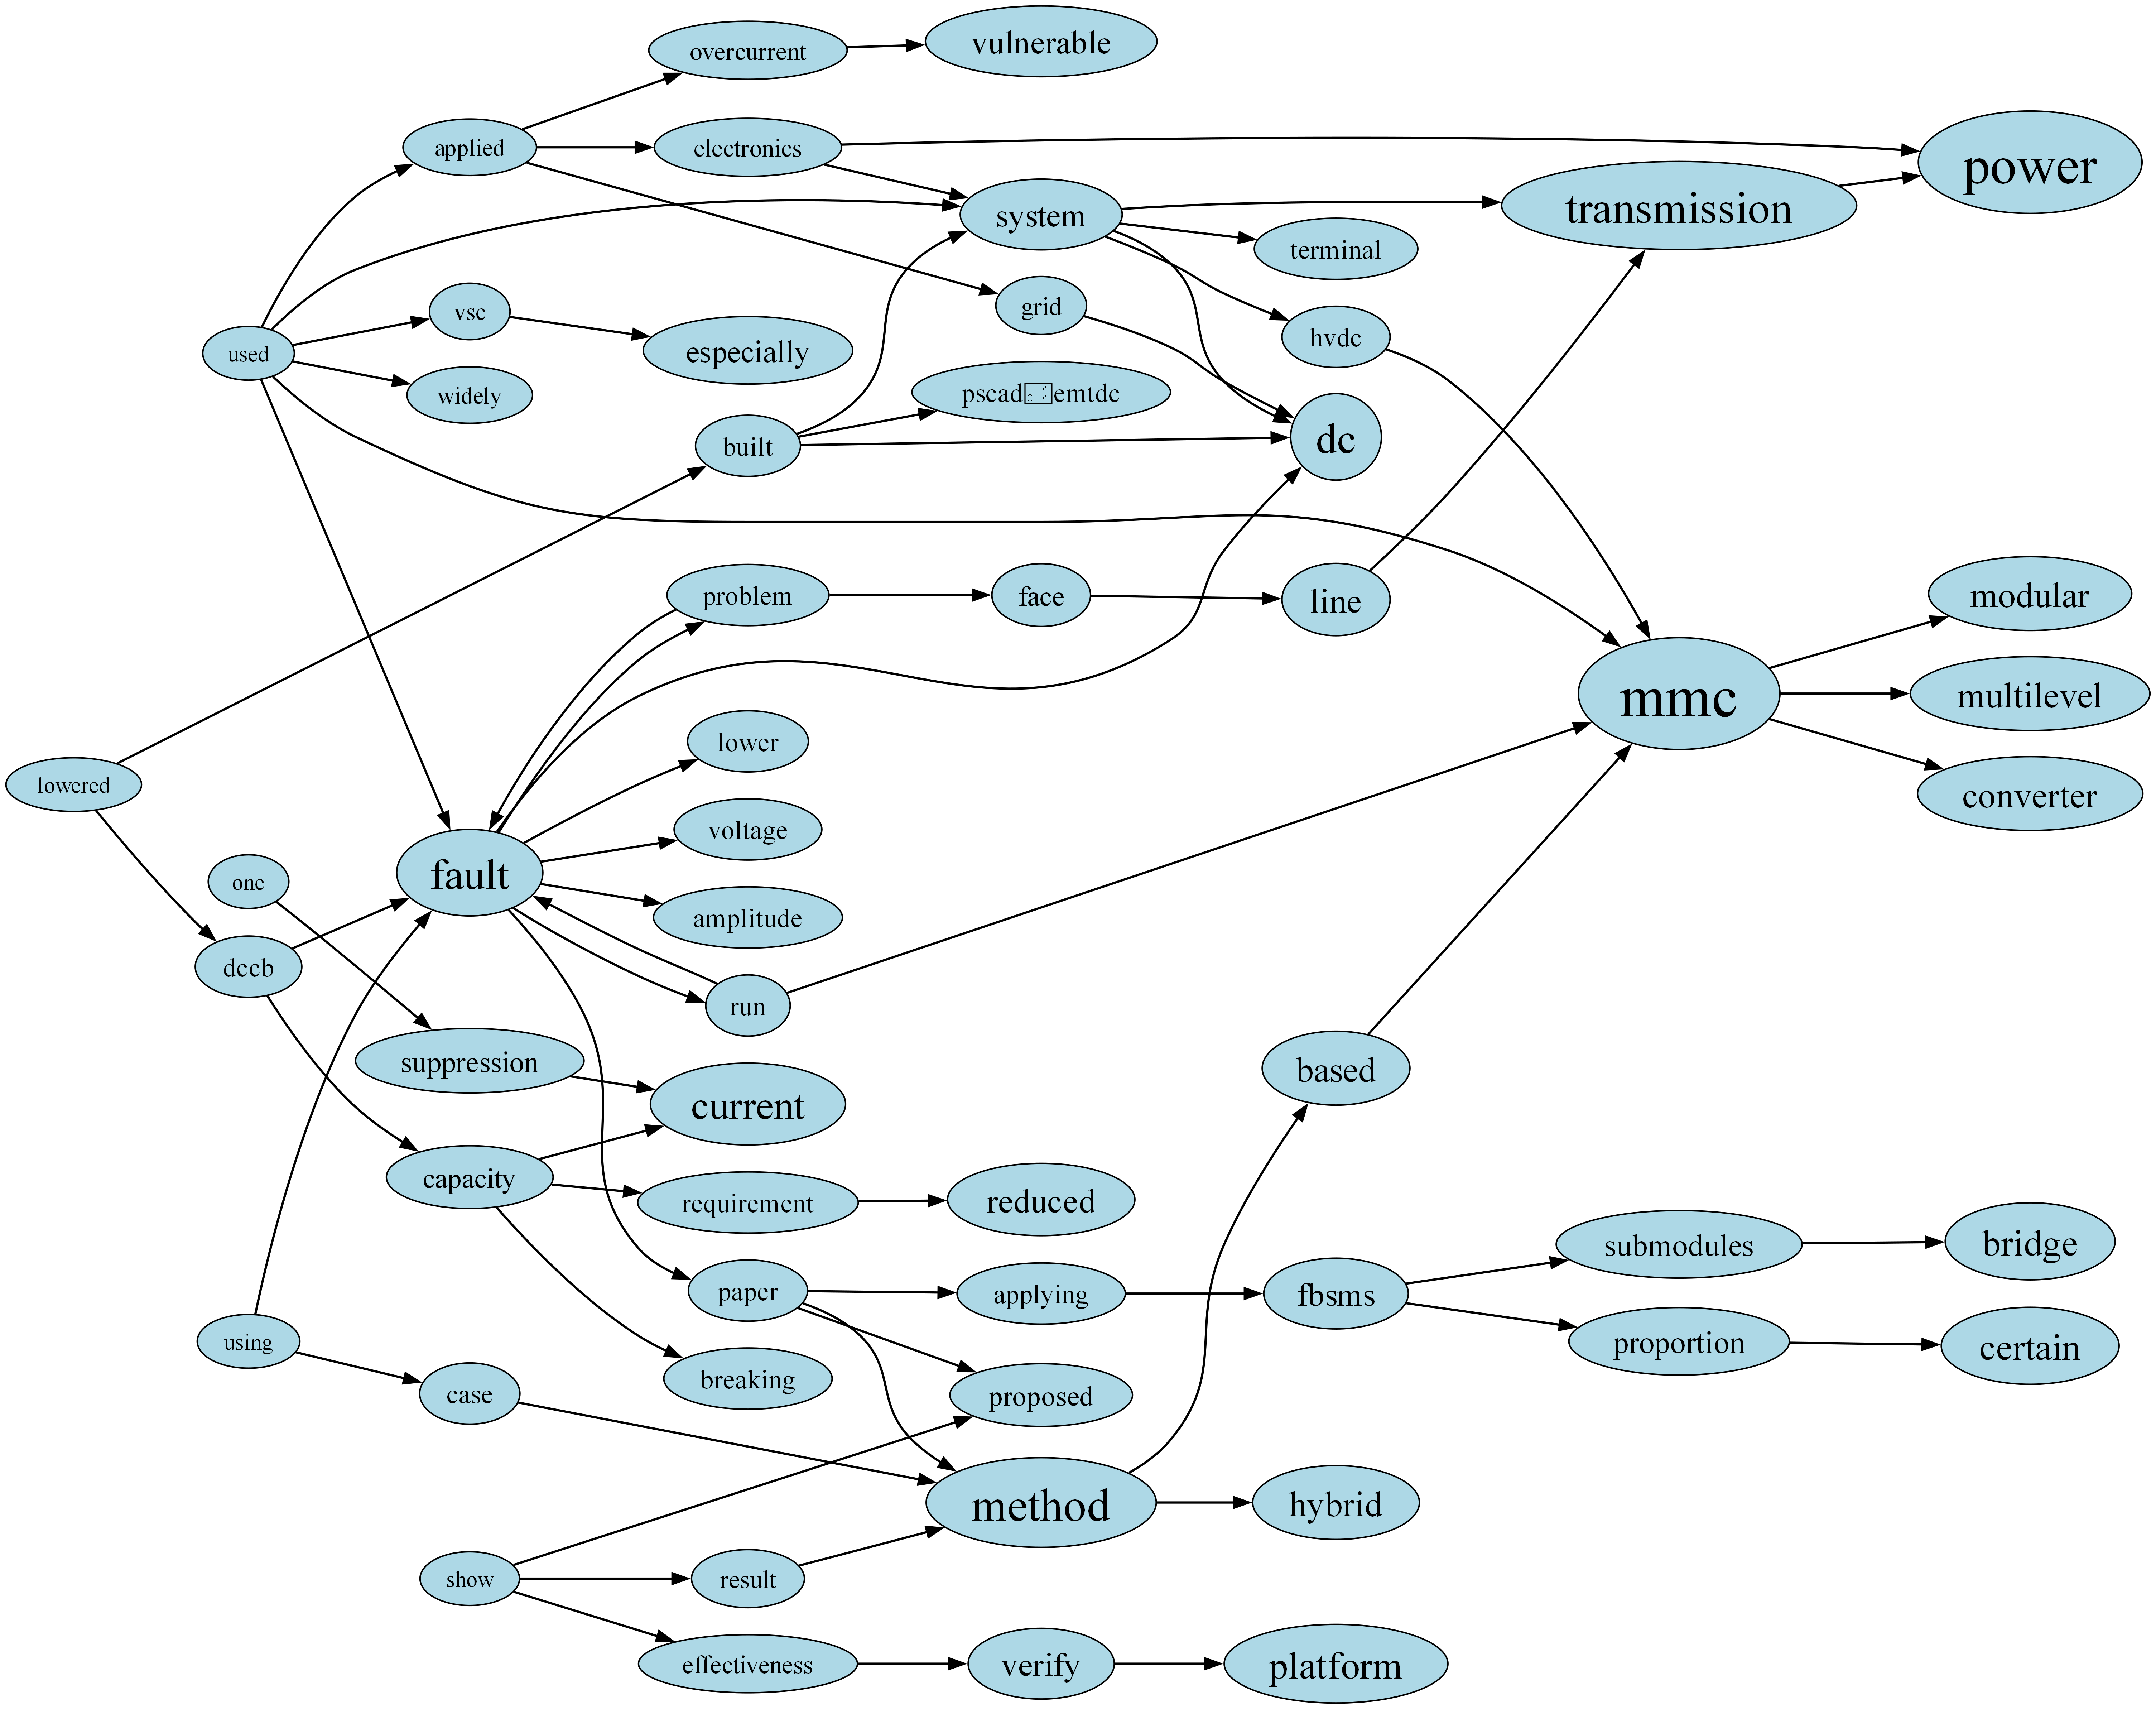

In [121]:
# Obtener el texto del dataframe
texto = df.iloc[1000]["Abstract"]

# Procesar el texto con spaCy
doc = nlp(texto)

# Crear grafo dirigido con NetworkX
G = nx.DiGraph()
for token in doc:
    if not token.is_stop and not token.is_punct:
        G.add_node(token.text)
    for child in token.children:
        if not child.is_stop and not child.is_punct:
            G.add_edge(token.text, child.text)

# Calcular importancia con PageRank
pagerank = nx.pagerank(G)

# Crear el grafo con Graphviz
dot = Digraph(format="png")
dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# Agregar nodos con tamaño basado en PageRank
max_pr = max(pagerank.values()) if pagerank else 1
for node, pr in pagerank.items():
    size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
    dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# Agregar aristas
for u, v in G.edges():
    dot.edge(u, v, color="black", penwidth="1.5")

# Renderizar el grafo en un archivo temporal
output_file = "Figuras/grafo"
dot.render(output_file, format="png", cleanup=True)
# Mostrar la imagen en Jupyter Notebook
display(Image(filename=output_file + ".png"))